# LSTM Baseline
File này thiết lập mô hình bộ nhớ dài hạn LSTM truyền thống để đối chiếu công bằng với mô hình Chronos-2 đã được fine-tune.
Để đảm bảo luật chơi "3 Chung" (Chung tập Train, chung tập Test 30 ngày, chung cách đánh giá), ta sẽ:
1. **Khắc phục Data Leakage:** Bơm thêm tập `Validation` (30 ngày trước Test) để model tự quyết định điểm dừng sớm (Early Stopping), giữ tập `Test` hoàn toàn đóng băng không được dòm ngó.
2. **Kéo dài Context Length:** `sequence_length = 60` (hoặc 180 tùy tài nguyên) để LSTM có đủ bộ nhớ về lịch sử.
3. **Đánh giá Inverse Transform:** Xuất về tiền thật (VND) để tính MAE, RMSE, MAPE đồng hạng với Chronos.

In [1]:
# ========== 1. IMPORT THƯ VIỆN & CẤU HÌNH ==========
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pickle
from IPython.display import display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Cấu hình thiết bị đang chạy: {device}")

# Thư mục lưu mô hình và các bộ Scaler
save_dir = "../../models/lstm_vn30"
os.makedirs(save_dir, exist_ok=True)

# THÔNG SỐ TRAINING
sequence_length = 180 # Lookback window (tương đương context_length của Chronos)
test_days = 30
val_days = 30
batch_size = 32
num_epochs = 250
patience = 25

Cấu hình thiết bị đang chạy: cuda


In [2]:
# ========== 2. KIẾN TRÚC MÔ HÌNH LSTM ==========
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout=0.2):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.linear(out[:, -1, :])
        return out

In [3]:
# ========== 3. CHUẨN BỊ DỮ LIỆU & TẠO SEQUENCE ==========

df_final = pd.read_csv('../../data/processed/merged_data_final.csv')
df_final['timestamp'] = pd.to_datetime(df_final['timestamp'])

# Resample tương tự Chronos để đồng nhất Time series
dfs = []
for ticker_id, group in df_final.groupby('id'):
    g_resampled = group.set_index('timestamp').resample('B').ffill()
    g_resampled['id'] = ticker_id
    dfs.append(g_resampled.reset_index())
df_ticker = pd.concat(dfs, ignore_index=True)

# Hàm hỗ trợ trượt cửa sổ
def create_sequences(X_data, y_data, seq_length):
    X_seq, y_seq = [], []
    for i in range(len(X_data) - seq_length):
        X_seq.append(X_data[i:i + seq_length])
        y_seq.append(y_data[i + seq_length])
    return np.array(X_seq), np.array(y_seq)

data_dict = {}

for ticker, group in df_ticker.groupby('id'):
    group = group.sort_values('timestamp').reset_index(drop=True)
    group = group.ffill().bfill()
    
    features = group.drop(['Close', 'timestamp', 'id'], axis=1).columns
    target = 'Close'
    
    N = len(group)
    val_start_idx = N - test_days - val_days
    test_start_idx = N - test_days

    # Phân chia dữ liệu. Chú ý tập Val và Test cần lấy dư ra khoảng thời gian sequence_length vào quá khứ.
    train_df = group.iloc[:val_start_idx]
    val_df = group.iloc[val_start_idx - sequence_length : test_start_idx]
    test_df = group.iloc[test_start_idx - sequence_length :]

    # Fit MinMaxScaler CHỈ trên tập Train (Tránh rò rỉ dữ liệu)
    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()

    train_X_scaled = scaler_X.fit_transform(train_df[features])
    train_y_scaled = scaler_y.fit_transform(train_df[[target]])

    val_X_scaled = scaler_X.transform(val_df[features])
    val_y_scaled = scaler_y.transform(val_df[[target]])

    test_X_scaled = scaler_X.transform(test_df[features])
    test_y_scaled = scaler_y.transform(test_df[[target]])

    # Lưu lại Scaler
    with open(f"{save_dir}/scaler_X_{ticker}.pkl", "wb") as f: pickle.dump(scaler_X, f)
    with open(f"{save_dir}/scaler_y_{ticker}.pkl", "wb") as f: pickle.dump(scaler_y, f)

    # Cắt sequence
    X_train_seq, y_train_seq = create_sequences(train_X_scaled, train_y_scaled, sequence_length)
    X_val_seq, y_val_seq = create_sequences(val_X_scaled, val_y_scaled, sequence_length)
    X_test_seq, y_test_seq = create_sequences(test_X_scaled, test_y_scaled, sequence_length)

    # Lưu vào buffer phục vụ training
    data_dict[ticker] = {
        'X_train': torch.tensor(X_train_seq, dtype=torch.float32), 'y_train': torch.tensor(y_train_seq, dtype=torch.float32),
        'X_val': torch.tensor(X_val_seq, dtype=torch.float32), 'y_val': torch.tensor(y_val_seq, dtype=torch.float32),
        'X_test': torch.tensor(X_test_seq, dtype=torch.float32), 'y_test': torch.tensor(y_test_seq, dtype=torch.float32),
        'input_size': len(features)
    }
print(f"✅ Đã chuẩn bị xong Dữ liệu cho {len(data_dict)} mã (Train/Val/Test)!")

✅ Đã chuẩn bị xong Dữ liệu cho 6 mã (Train/Val/Test)!


In [4]:
# ========== 4. TIẾN HÀNH HUẤN LUYỆN ==========

for ticker, d in data_dict.items():
    print(f"\n--- Đang Train: {ticker} ---")
    
    model = LSTMModel(input_size=d['input_size'], hidden_size=128, num_layers=1, output_size=1, dropout=0.1).to(device)
    loss_fn = nn.MSELoss(reduction='mean')
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    train_loader = DataLoader(TensorDataset(d['X_train'], d['y_train']), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(d['X_val'], d['y_val']), batch_size=batch_size, shuffle=False)

    best_loss = float('inf')
    patience_counter = 0
    best_model_path = f'{save_dir}/best_model_{ticker}.pth'

    for epoch in range(num_epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()

        # Đánh giá trên tập Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_X_val, batch_y_val in val_loader:
                batch_X_val, batch_y_val = batch_X_val.to(device), batch_y_val.to(device)
                val_loss += loss_fn(model(batch_X_val), batch_y_val).item()
        val_loss /= len(val_loader)

        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), best_model_path)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"  -> Bắt đáy Early stopping tại epoch {epoch+1}. Best Val Loss: {best_loss:.4f}")
                break


--- Đang Train: FPT ---


c:\Users\admin\miniconda3\envs\env_core\lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.1 and num_layers=1
  warnings.warn(


  -> Bắt đáy Early stopping tại epoch 121. Best Val Loss: 0.0003

--- Đang Train: HPG ---


c:\Users\admin\miniconda3\envs\env_core\lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.1 and num_layers=1
  warnings.warn(


  -> Bắt đáy Early stopping tại epoch 84. Best Val Loss: 0.0003

--- Đang Train: SSI ---
  -> Bắt đáy Early stopping tại epoch 49. Best Val Loss: 0.0006

--- Đang Train: VCB ---
  -> Bắt đáy Early stopping tại epoch 120. Best Val Loss: 0.0001

--- Đang Train: VHM ---
  -> Bắt đáy Early stopping tại epoch 79. Best Val Loss: 0.0037

--- Đang Train: VNM ---
  -> Bắt đáy Early stopping tại epoch 43. Best Val Loss: 0.0004


In [5]:
# ========== 5. ĐÁNH GIÁ TRÊN TẬP TEST (INFERENCE) ==========
all_metrics = []

for ticker, d in data_dict.items():
    # Load model và scaler
    best_model_path = f'{save_dir}/best_model_{ticker}.pth'
    model = LSTMModel(input_size=d['input_size'], hidden_size=128, num_layers=1, output_size=1, dropout=0).to(device)
    model.load_state_dict(torch.load(best_model_path, weights_only=True))
    model.eval()
    
    with open(f"{save_dir}/scaler_y_{ticker}.pkl", "rb") as f:
        scaler_y = pickle.load(f)

    # Inference trên tập Test
    with torch.no_grad():
        preds_scaled = model(d['X_test'].to(device)).cpu().numpy()
        true_scaled = d['y_test'].numpy()

    # Xả scale về VND
    y_pred = scaler_y.inverse_transform(preds_scaled).flatten()
    y_true = scaler_y.inverse_transform(true_scaled).flatten()
    
    # Lưu kết quả dự báo để vẽ biểu đồ ở Cell sau
    d['y_pred_unscaled'] = y_pred
    
    # Tính Metric
    mae = np.mean(np.abs(y_pred - y_true))
    rmse = np.sqrt(np.mean((y_pred - y_true) ** 2))
    mape = np.mean(np.abs((y_pred - y_true) / y_true)) * 100
    
    all_metrics.append({
        'Mã CK': ticker,
        'LSTM MAE': mae,
        'LSTM RMSE': rmse,
        'LSTM MAPE (%)': mape
    })

metrics_df = pd.DataFrame(all_metrics).round(3)
display(metrics_df)

print("\n=> HIỆU NĂNG LSTM (30 NGÀY TEST):")
print(f"  • MAE  : {metrics_df['LSTM MAE'].mean():.4f} VND")
print(f"  • RMSE : {metrics_df['LSTM RMSE'].mean():.4f} VND")
print(f"  • MAPE : {metrics_df['LSTM MAPE (%)'].mean():.2f} %")

,Mã CK,LSTM MAE,LSTM RMSE,LSTM MAPE (%)
0,FPT,1.451,1.725,1.524
1,HPG,0.319,0.386,1.194
2,SSI,0.545,0.672,1.817
3,VCB,0.412,0.545,0.712
4,VHM,3.394,4.385,3.133
5,VNM,0.995,1.295,1.590



=> HIỆU NĂNG LSTM (30 NGÀY TEST):
  • MAE  : 1.1860 VND
  • RMSE : 1.5013 VND
  • MAPE : 1.66 %


🎨 Đang xuất biểu đồ dự báo cho các mã...


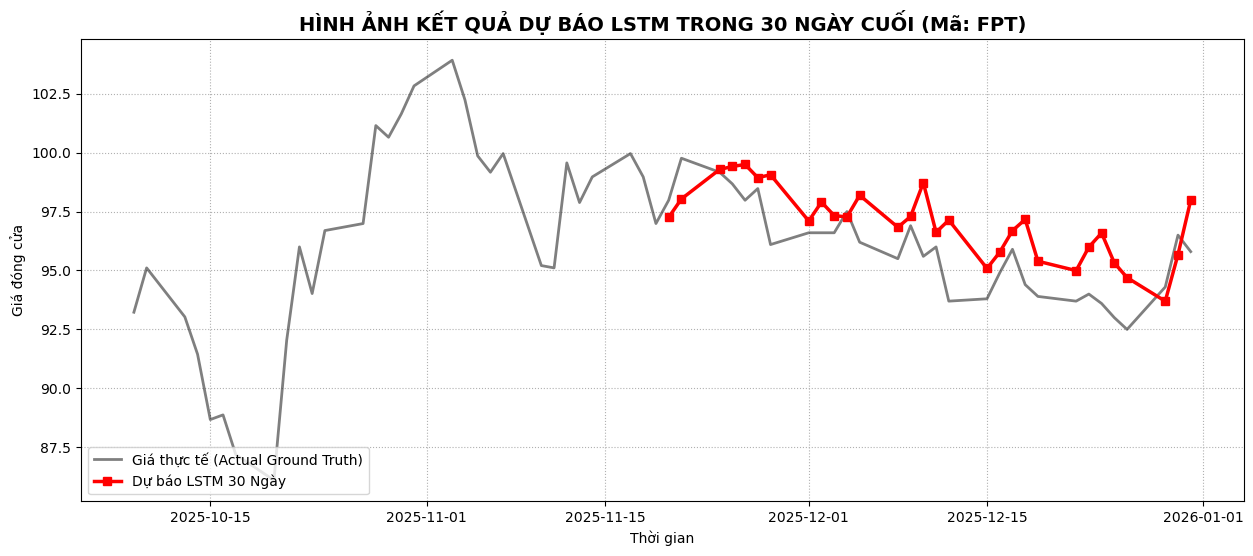

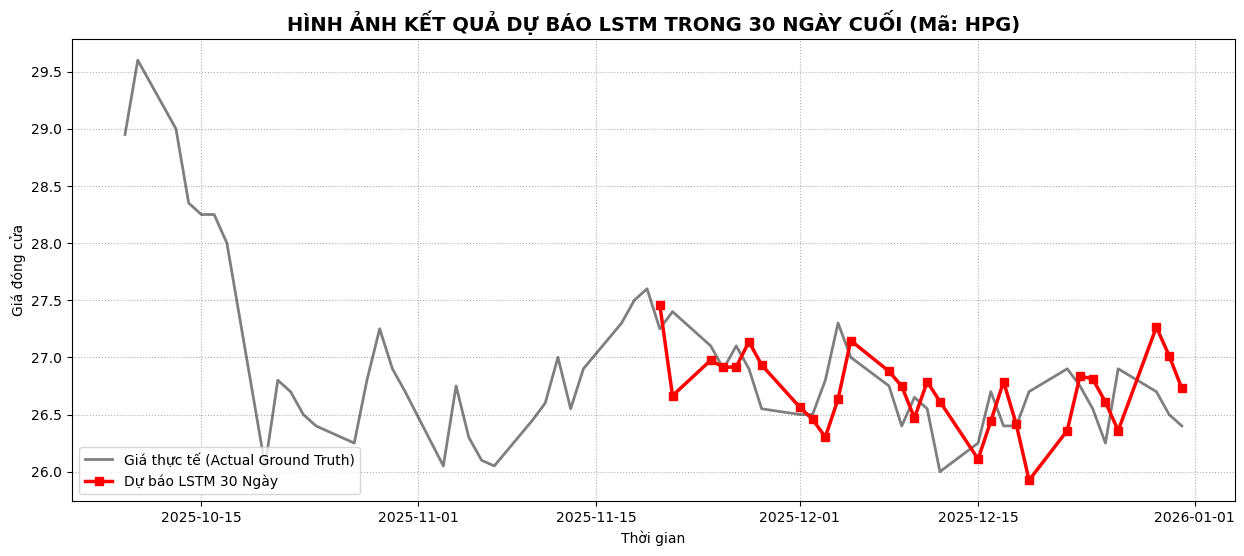

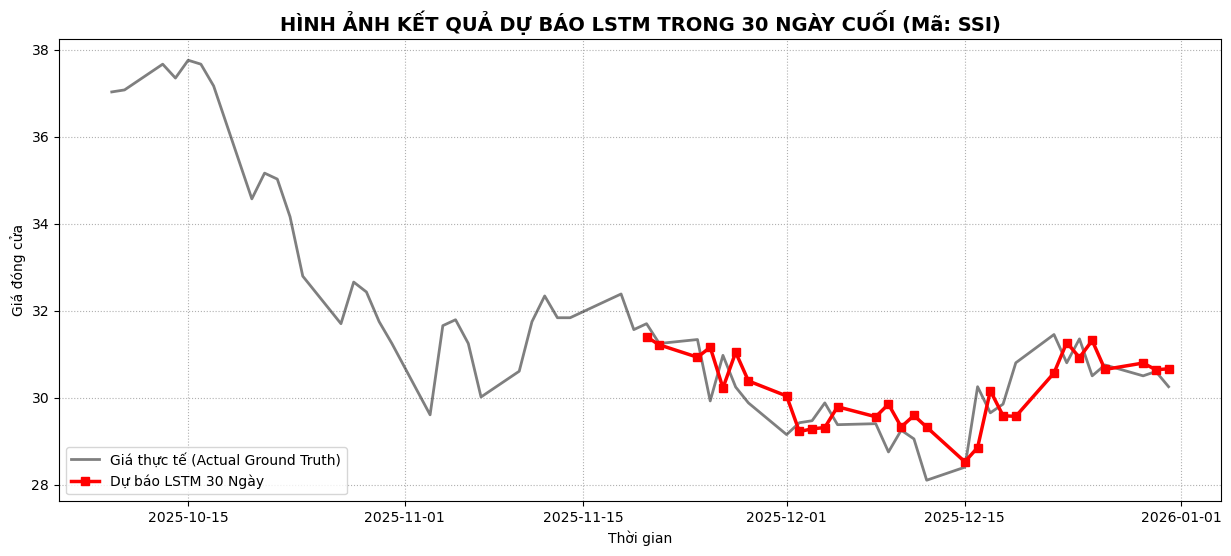

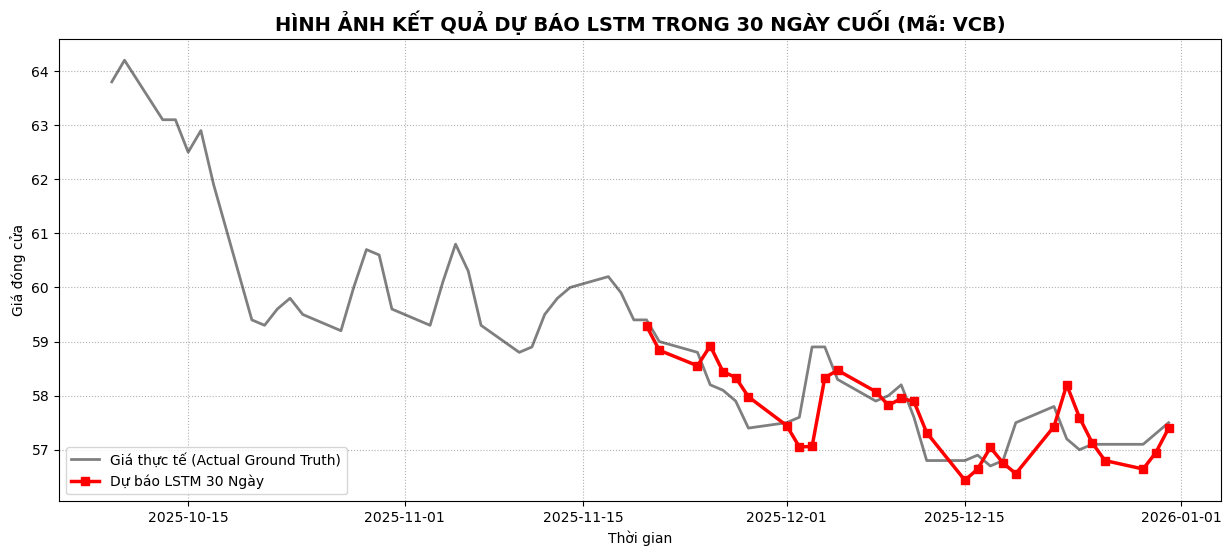

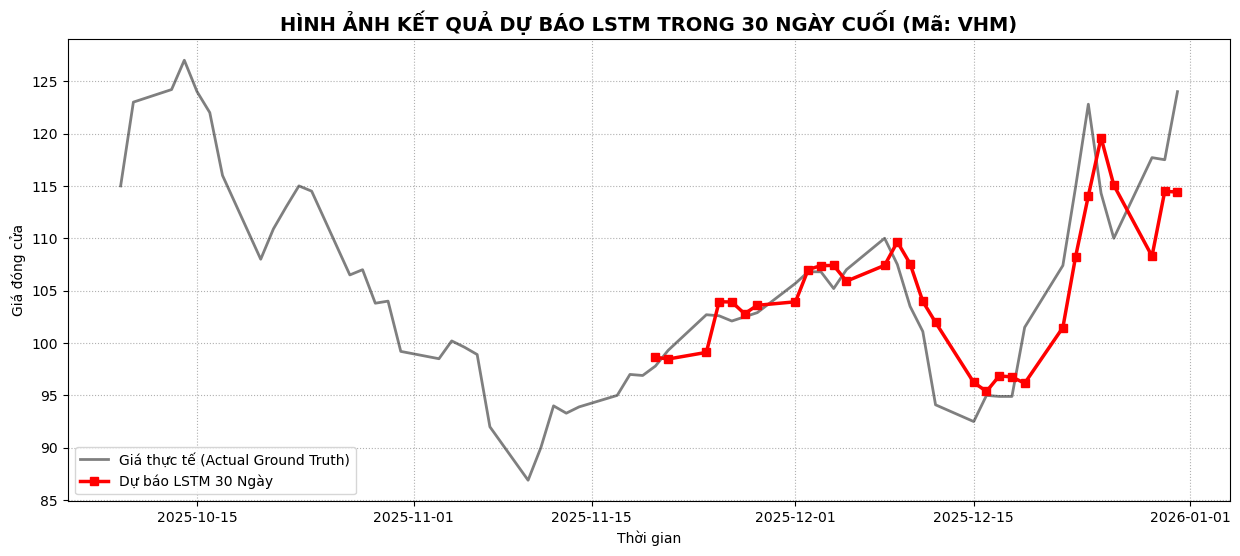

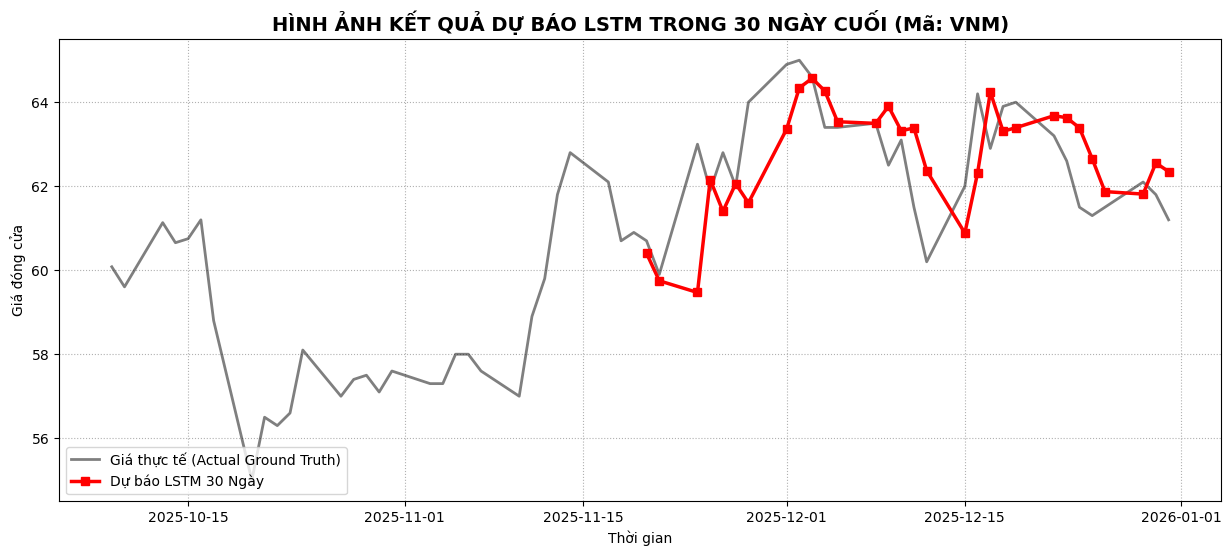

In [6]:
# ========== 6. TRỰC QUAN HÓA KẾT QUẢ DỰ BÁO LSTM ==========
def plot_lstm_results(ticker):
    plt.figure(figsize=(15, 6))
    
    # Lấy dữ liệu đoạn sau để hiển thị 
    days_to_show = 60
    df_hist = df_ticker[df_ticker['id'] == ticker].tail(days_to_show)
    
    # 1. Đường giá thực tế
    plt.plot(df_hist['timestamp'], df_hist['Close'], label='Giá thực tế (Actual Ground Truth)', color='black', alpha=0.5, linewidth=2)
    
    # 2. Đường dự báo LSTM (30 ngày cuối)
    d = data_dict[ticker]
    y_pred = d['y_pred_unscaled']
    test_timestamps = df_hist['timestamp'].tail(test_days)
    
    plt.plot(test_timestamps, y_pred, label='Dự báo LSTM 30 Ngày', color='red', linestyle='-', linewidth=2.5, marker='s')
    
    plt.title(f'HÌNH ẢNH KẾT QUẢ DỰ BÁO LSTM TRONG 30 NGÀY CUỐI (Mã: {ticker})', fontweight='bold', fontsize=14)
    plt.xlabel('Thời gian')
    plt.ylabel('Giá đóng cửa')
    plt.grid(True, linestyle=":")
    plt.legend(loc='lower left')
    plt.show()

# Vẽ 6 mã cổ phiếu đầu tiên
tickers_to_plot = list(data_dict.keys())[:6]
print("🎨 Đang xuất biểu đồ dự báo cho các mã...")
for tc in tickers_to_plot:
    plot_lstm_results(tc)